# Game modeling: xG, xT, control, passing and possession value

Implement simple models directly, with explicit targets and boundaries between fitted data, physical assumptions and illustrative calculations.

Download the bounded real sample first with `python scripts/download_data.py` from the repository root. Run cells in order. Each notebook can start a fresh kernel. Only data ingestion and pitch drawing use shared helpers; calculations below use NumPy/pandas/SciPy directly. Raw files remain excluded from Git. The sample contains one partial first half, so supervised-model training requires additional labeled matches for meaningful evaluation.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'workshop.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import load_data, pitch  # ingestion and drawing only; methods below are explicit
dataset, wide, tracking, metadata, events, phases, raw = load_data()
tracking = tracking.sort_values(['player_id','period_id','frame_id']).copy()
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
observed = tracking.dropna(subset=['x','y'])
frame_id = int(observed.groupby(['period_id','frame_id']).size().loc[lambda s:s.eq(22)].index[20][1])
snapshot = observed[observed.frame_id.eq(frame_id)].copy()
keepers = {str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels = {str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
print('Real match 1925299; loaded frames:', wide.shape[0], '| illustrative frame:', frame_id)

Real match 1925299; loaded frames: 6153 | illustrative frame: 61


## xG features and a binary classifier
Distance and goal-opening angle are a starting feature set. Tracking adds goalkeeper location and defenders in the shooting corridor. Training needs real shot outcomes over many matches. We expose logistic loss and its gradient, using a synthetic optimizer check rather than inventing xG probabilities on this sample.

In [2]:
def shot_features(x,y):
    dx=52.5-np.asarray(x);y=np.asarray(y)
    distance=np.hypot(dx,y)
    a=np.arctan2(3.66-y,dx);b=np.arctan2(-3.66-y,dx)
    angle=np.abs(np.angle(np.exp(1j*(a-b))))
    return np.c_[distance,angle]
def sigmoid(z):return 1/(1+np.exp(-np.clip(z,-40,40)))
def fit_binary(X,y,steps=1000,lr=.1):
    X=np.c_[np.ones(len(X)),np.asarray(X,float)];w=np.zeros(X.shape[1]);y=np.asarray(y,float)
    for _ in range(steps):w-=lr*X.T@(sigmoid(X@w)-y)/len(y)
    return w
display(pd.DataFrame(shot_features([40,30,45],[0,15,-10]),columns=['distance_m','opening_radians']))
rng=np.random.default_rng(8);toy=rng.normal(size=(100,2));target=(toy[:,0]>0).astype(int);w=fit_binary(toy,target)
assert ((sigmoid(np.c_[np.ones(len(toy)),toy]@w)>.5)==target).mean()>.9
print('Synthetic optimization check only. No real xG fit is claimed.')

,distance_m,opening_radians
0,12.500000,0.569677
1,27.041635,0.225530
2,12.500000,0.366905


Synthetic optimization check only. No real xG fit is claimed.


## xT as a Markov reward model, from scratch
For each state, count shots, goals and attempted movements. Estimate `p_shot`, scoring conditional on shooting, and successful transition probability per **all state actions**. Failed moves contribute zero continuation in this formulation. Iterate `V = immediate_goal_reward + successful_transition @ V`. The function accepts an action table and trains the grid; the demonstration uses clearly synthetic actions because the supplied dynamic-event schema is not a complete verified shot/move training corpus. [Karun Singh](https://karun.in/blog/expected-threat.html).

Synthetic fitted values: [0.25 0.5 ]


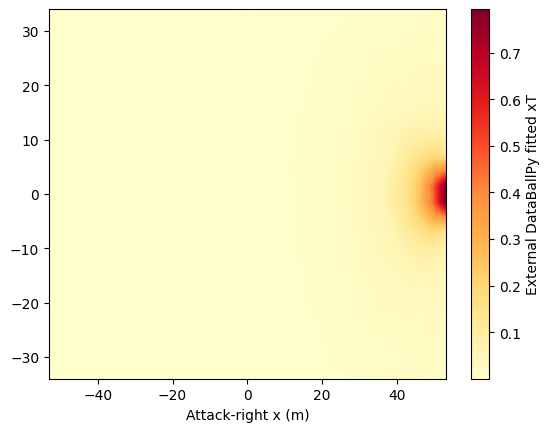

In [3]:
def fit_xt(actions,n_states,tolerance=1e-10,max_iter=10000):
    totals=np.bincount(actions.start,minlength=n_states).astype(float)
    reward=np.zeros(n_states);transitions=np.zeros((n_states,n_states))
    for a in actions.itertuples():
        if a.kind=='shot':reward[a.start]+=float(a.goal)
        elif a.success:transitions[a.start,int(a.end)]+=1
    denominator=np.maximum(totals,1)
    reward/=denominator;transitions/=denominator[:,None]
    V=np.zeros(n_states)
    for _ in range(max_iter):
        next_V=reward+transitions@V
        if np.max(np.abs(next_V-V))<tolerance:return next_V,transitions,reward
        V=next_V
    raise ValueError('xT did not converge; inspect recurrent states and termination')
toy_actions=pd.DataFrame([dict(start=0,end=1,kind='move',success=True,goal=False),dict(start=0,end=1,kind='move',success=False,goal=False),dict(start=1,end=1,kind='shot',success=False,goal=True),dict(start=1,end=1,kind='shot',success=False,goal=False)])
V,T,reward=fit_xt(toy_actions,2);assert np.allclose(V,[.25,.5]);print('Synthetic fitted values:',V)
# Compare with an external event-trained model, explicitly distinct from fitting above.
grid=np.load(ROOT/'resources/models/open_play_xT.npy');plt.imshow(grid.T,origin='lower',extent=(-53,53,-34,34),aspect='auto',cmap='YlOrRd');plt.colorbar(label='External DataBallPy fitted xT');plt.xlabel('Attack-right x (m)');plt.show()

## Voronoi and Gaussian influence
Voronoi assigns each grid point to its nearest player. Our anisotropic Gaussian is an explicit teaching model: longer influence along velocity and a half-second projected centre. It is not Fernández/Bornn's exact parameterization. A bounded influence difference is a score, not a calibrated probability. Compare sensitivity to scale.

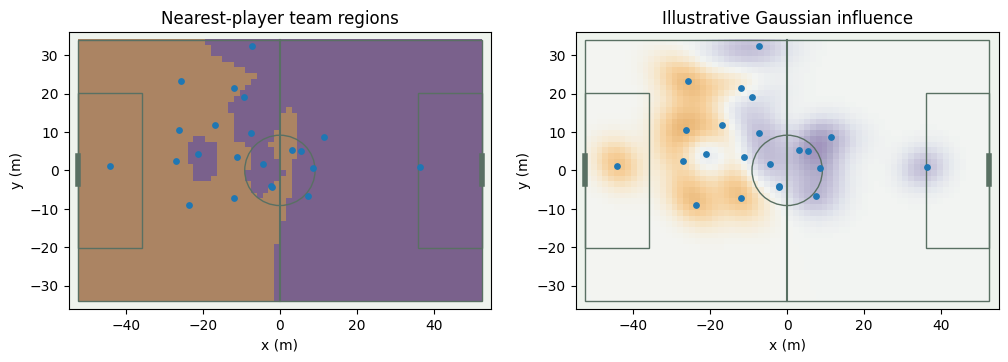

In [4]:
X,Y=np.meshgrid(np.linspace(-52.5,52.5,70),np.linspace(-34,34,46));targets=np.stack([X,Y],axis=-1)
nodes=snapshot.reset_index(drop=True);positions=nodes[['x','y']].to_numpy();home=nodes.team_id.eq(1802).to_numpy()
distance=np.linalg.norm(targets[:,:,None,:]-positions,axis=-1)
voronoi=home[distance.argmin(axis=-1)].astype(float)
# Backward finite difference on consecutive observations; no future velocity features.
previous=observed[observed.frame_id.eq(frame_id-1)][['player_id','x','y','seconds']]
nodes=nodes.merge(previous,on='player_id',suffixes=('','_previous'),how='left')
dt=nodes.seconds-nodes.seconds_previous
velocity=(nodes[['x','y']].to_numpy()-nodes[['x_previous','y_previous']].to_numpy())/dt.to_numpy()[:,None]
velocity=np.nan_to_num(velocity);influence=[]
for p,v in zip(positions,velocity):
    speed=np.linalg.norm(v);u=v/speed if speed>.01 else np.array([1.,0.]);perp=np.array([-u[1],u[0]])
    delta=targets-(p+.5*v);major=4+.7*min(speed,8)
    influence.append(np.exp(-.5*((delta@u/major)**2+(delta@perp/4)**2)))
influence=np.stack(influence,axis=-1);gaussian=sigmoid(influence[:,:,home].sum(axis=-1)-influence[:,:,~home].sum(axis=-1))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,surface,title in zip(axs,[voronoi,gaussian],['Nearest-player team regions','Illustrative Gaussian influence']):
    pitch(ax);ax.imshow(surface,origin='lower',extent=(-52.5,52.5,-34,34),cmap='PuOr',alpha=.6,vmin=0,vmax=1);ax.scatter(positions[:,0],positions[:,1],s=15);ax.set_title(title)
plt.show()

## Arrival time and pass-interception survival
Start with reaction plus travel time to each target. Then sample a hypothetical pass path, compare player arrival with ball arrival, and integrate interception hazards. The expected receiver and passer are specified. This is our simplified constant-speed hazard model, not exact Spearman or the `accessible-space` implementation. Parameters need fitting and calibration against real passes.

,player_id,completion_proxy
1,287934,0.997385
3,50999,0.998806
4,51002,0.999949
5,51043,0.993757
6,51050,0.999493
8,560882,0.999895
9,560983,0.999853
12,560986,0.977163
16,795537,0.808715
17,797298,0.978780


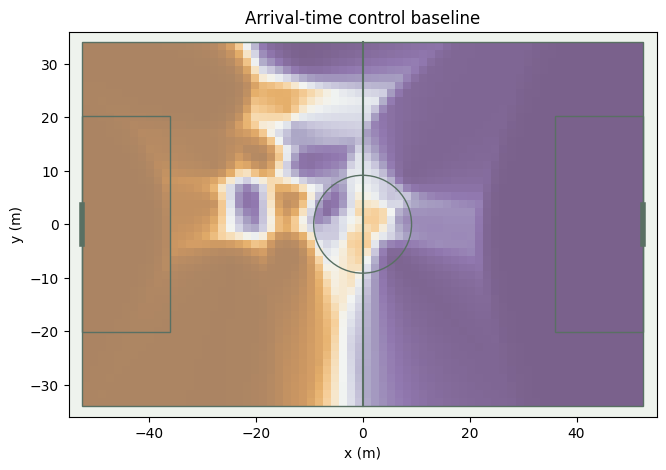

In [5]:
reaction=.7;player_speed=5.
arrival=reaction+np.linalg.norm(targets[:,:,None,:]-(positions+.7*velocity),axis=-1)/player_speed
control=sigmoid((arrival[:,:,~home].min(axis=-1)-arrival[:,:,home].min(axis=-1))/.45)
def pass_survival(start,end,defender_positions,ball_speed=15.,reaction=.7,run_speed=5.,rate=2.):
    duration=np.linalg.norm(end-start)/ball_speed
    if duration<1e-9:return 1.
    times=np.linspace(0,duration,40);path=start+(end-start)*times[:,None]/duration
    arrival=reaction+np.linalg.norm(path[:,None,:]-defender_positions[None,:,:],axis=-1)/run_speed
    hazards=rate*sigmoid((times[:,None]-arrival)/.15)
    # Probability of no defender interception under this independent-hazard approximation.
    return float(np.exp(-np.trapezoid(hazards.sum(axis=1),times)))
ball=wide[wide.frame_id.eq(frame_id)].iloc[0];start=np.array([ball.ball_x,ball.ball_y])
options=nodes[nodes.team_id.eq(1802)].copy()
options['completion_proxy']=[pass_survival(start,np.array([r.x,r.y]),positions[~home]) for r in options.itertuples()]
display(options[['player_id','completion_proxy']]);assert options.completion_proxy.between(0,1).all()
plt.figure(figsize=(8,5));pitch(plt.gca());plt.imshow(control,origin='lower',extent=(-52.5,52.5,-34,34),alpha=.6,cmap='PuOr',vmin=0,vmax=1);plt.title('Arrival-time control baseline');plt.show()

## Accessible and dangerous space proxies
Integrate a reachability surface over cell area. Danger weighting adds an explicitly chosen goal-distance weight. This illustrative integral explains the mechanics but is not the published AS/DAS metric. The main walkthrough calls the actual `accessible-space` package. Recompute after a run to study change, keeping opponents and context visible.

Reachability integral proxy (m²): 4242.8
Danger-weighted proxy (weighted m²): 276.6


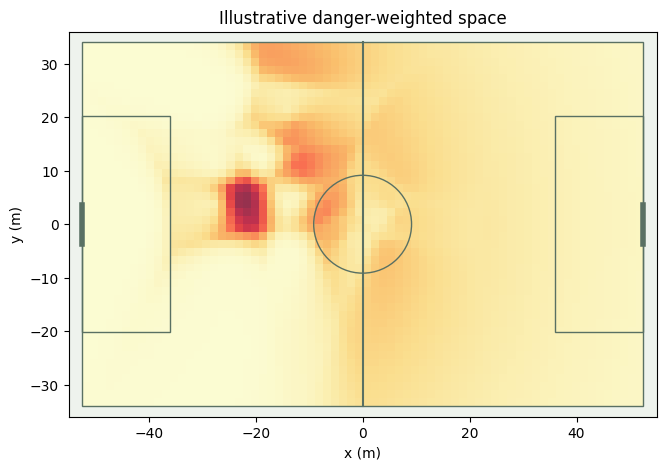

In [6]:
cell_area=(X[0,1]-X[0,0])*(Y[1,0]-Y[0,0])
# Brisbane attacks left: its target goal is x=-52.5 in this sample.
danger=np.exp(-np.hypot(X+52.5,Y)/25)
accessible_proxy=float(control.sum()*cell_area)
dangerous_proxy=float((control*danger).sum()*cell_area)
print('Reachability integral proxy (m²):',round(accessible_proxy,1))
print('Danger-weighted proxy (weighted m²):',round(dangerous_proxy,1))
fig,ax=plt.subplots(figsize=(8,5));pitch(ax);ax.imshow(control*danger,origin='lower',extent=(-52.5,52.5,-34,34),alpha=.8,cmap='YlOrRd');ax.set_title('Illustrative danger-weighted space');plt.show()

## Off-ball run threat and EPV decomposition
An unserved run can change options and danger even without an event. A simple proxy uses completion times destination value; compare before and after a run rather than crediting all endpoint value to the runner. SkillCorner's run xthreat is a supplied distinct model.

EPV requires a precisely defined target. A generic action decomposition sums action-selection probabilities times success/failure conditional values. Bekkers' GraphEPV instead predicts a goal within ten seconds directly from a frame graph. The formula below illustrates decomposition with hypothetical inputs, not learned predictions.

In [7]:
def lookup_xt(x,y):
    nx,ny=grid.shape;ix=np.clip(((x+53)/106*nx).astype(int),0,nx-1);iy=np.clip(((y+34)/68*ny).astype(int),0,ny-1)
    return grid[ix,iy]
options['destination_xT']=lookup_xt(-options.x.to_numpy()*106/105,-options.y.to_numpy())
options['option_proxy']=options.completion_proxy*options.destination_xT
display(options[['player_id','completion_proxy','destination_xT','option_proxy']].sort_values('option_proxy',ascending=False))
def decomposed_epv(selection,success,value_success,value_failure):
    selection=np.asarray(selection,float);success=np.asarray(success,float)
    if not np.isclose(selection.sum(),1) or (selection<0).any():raise ValueError('Action selection must be a distribution')
    return float(np.sum(selection*(success*np.asarray(value_success)+(1-success)*np.asarray(value_failure))))
print('Hypothetical decomposition:',decomposed_epv([.6,.4],[.8,.5],[.05,.15],[-.02,-.04]))

,player_id,completion_proxy,destination_xT,option_proxy
16,795537,0.808715,0.015401,0.012455
8,560882,0.999895,0.007392,0.007392
4,51002,0.999949,0.007129,0.007129
17,797298,0.978780,0.006698,0.006556
12,560986,0.977163,0.006086,0.005947
1,287934,0.997385,0.004987,0.004974
9,560983,0.999853,0.004722,0.004722
5,51043,0.993757,0.004298,0.004271
6,51050,0.999493,0.004265,0.004263
19,965697,0.995116,0.003884,0.003865


Hypothetical decomposition: 0.0436


## Evaluation and next steps
Hold out matches, not neighboring frames. Assess discrimination **and calibration** for xG, pass completion and GraphEPV. Compare models on the same horizon and target. Use real action labels to fit xT, real shots to fit xG, and synchronized goals to train EPV. The proxy quantities above must not be reported as official provider metrics. Read [Fernández EPV](https://pmc.ncbi.nlm.nih.gov/articles/PMC8570314/), [Bekkers GraphEPV](https://rawcdn.githack.com/UnravelSports/keynotes/main/html/20250607-PyData-London.html) and [DataBallPy](https://databallpy.readthedocs.io/en/main/).